<h1 style="
    background: linear-gradient(135deg, #F3E9D2, #E8D5B7);
    color: #000000;
    padding: 22px;
    border-radius: 12px;
    text-align: center;
    font-size: 32px;
    font-weight: 700;
    letter-spacing: 1px;
    border: 1px solid #D4B896;
    box-shadow: 0 4px 12px rgba(0, 0, 0, 0.12);
">
    📣 Marketing Campaign & Customer Behavior Analysis
</h1>

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
df = pd.read_csv("marketing_campaign_customer_behavior.csv")

## Checking the first 5 rows
This helps us understand what the dataset actually looks like.

In [3]:
df.head()

,customer_id,age,gender,income,region,device,customer_segment,loyalty_member,date,time_of_day,channel,campaign_name,creative_type,impressions,clicks,conversions,discount_used,spend,revenue
0,102886,29.0,Other,74800.0,North,Mobile,Churned,Yes,2024-10-09,Night,Google Ads,Weekend Special,Text,654,17,0,No,26.27,0.00
1,100343,29.0,Male,47600.0,West,Tablet,Returning Customer,Yes,2023-09-06,Afternoon,Youtube Ads,Back to School,Video,913,13,0,No,8.71,0.00
2,103416,29.0,Female,53000.0,West,Tablet,New Customer,Yes,2024-08-24,Afternoon,IG,Product Launch,Carousel,103,2,0,No,2.10,0.00
3,103226,24.0,Female,72600.0,West,Mobile,Returning Customer,No,2023-12-15,Afternoon,GoogleAds,Festive Offer,Text,3798,145,7,No,258.13,503.81
4,100480,21.0,Male,96900.0,East,Desktop,Returning Customer,Yes,2023-07-07,Night,Google Ads,Flash Deal,Video,2052,78,4,No,157.39,421.08


## Data Understanding

The dataset contains marketing campaign and customer behavior data, including customer demographics, income, region, device usage, customer segments, campaign details, engagement metrics, discounts, spending, and revenue. It can be used to analyze customer behavior, campaign performance, conversion rates, and revenue generation.

## Checking the last 5 rows
This is just a quick check that the dataset has been loaded completely.

In [4]:
df.tail()

,customer_id,age,gender,income,region,device,customer_segment,loyalty_member,date,time_of_day,channel,campaign_name,creative_type,impressions,clicks,conversions,discount_used,spend,revenue
14667,101226,25.0,Male,23900.0,East,Desktop,VIP,Yes,2023-05-26,Night,google ads,Product Launch,Image,1201,37,3,Yes,40.86,324.37
14668,103202,37.0,Other,51800.0,North,Desktop,Returning Customer,Yes,2024-03-17,Evening,instagram,Product Launch,Image,461,15,0,No,17.61,0.00
14669,101273,28.0,Male,59600.0,East,Tablet,Churned,No,2024-05-21,Evening,Email,App Install Push,Image,514,26,0,No,4.47,0.00
14670,100206,42.0,Other,36400.0,East,Mobile,Churned,No,2024-04-01,Evening,IG,Loyalty Rewards,Image,816,31,0,No,28.56,0.00
14671,101725,34.0,Female,75700.0,South,Mobile,Returning Customer,No,2024-06-13,Morning,Tik Tok,Summer Sale,Text,7897,63,1,No,28.34,49.73


## No.of Rows and Columns

In [5]:
df.shape

(14672, 19)

The dataset has 14672 rows and 19 columns

## Checking the column names
Helps to understand the names of the columns present in the dataset


In [6]:
df.columns

Index(['customer_id', 'age', 'gender', 'income', 'region', 'device',
       'customer_segment', 'loyalty_member', 'date', 'time_of_day', 'channel',
       'campaign_name', 'creative_type', 'impressions', 'clicks',
       'conversions', 'discount_used', 'spend', 'revenue'],
      dtype='str')

In [7]:
#if you want them as a normal Python list:
#df.columns.tolist()

In [8]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

## Understanding the dataset structure

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14672 entries, 0 to 14671
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       14672 non-null  int64  
 1   age               14402 non-null  float64
 2   gender            14672 non-null  str    
 3   income            14206 non-null  float64
 4   region            14452 non-null  str    
 5   device            14672 non-null  str    
 6   customer_segment  14672 non-null  str    
 7   loyalty_member    14672 non-null  str    
 8   date              14672 non-null  str    
 9   time_of_day       14672 non-null  str    
 10  channel           14672 non-null  str    
 11  campaign_name     14672 non-null  str    
 12  creative_type     14672 non-null  str    
 13  impressions       14672 non-null  int64  
 14  clicks            14672 non-null  int64  
 15  conversions       14672 non-null  int64  
 16  discount_used     14672 non-null  str    
 17  spen

The dataset has 19 columns,14,672 rows ,numerical columns,categorical columns,date column and some  missing values

## Checking data types

In [10]:
df.dtypes

customer_id           int64
age                 float64
gender                  str
income              float64
region                  str
device                  str
customer_segment        str
loyalty_member          str
date                    str
time_of_day             str
channel                 str
campaign_name           str
creative_type           str
impressions           int64
clicks                int64
conversions           int64
discount_used           str
spend               float64
revenue             float64
dtype: object

## Checking missing values

In [11]:
df.isnull().sum()

customer_id           0
age                 270
gender                0
income              466
region              220
device                0
customer_segment      0
loyalty_member        0
date                  0
time_of_day           0
channel               0
campaign_name         0
creative_type         0
impressions           0
clicks                0
conversions           0
discount_used         0
spend                 0
revenue               0
dtype: int64

In this dataset the age column has 270 missing values,income column has 466 missing values and region column has 220 missing values .956 missing values in total

## Checking duplicate rows

In [12]:
df.duplicated().sum()

np.int64(138)

The dataset has currently 138 duplicate rows

In [13]:
df = df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.shape

(14534, 19)

After removing the duplicate values we have 19 columns and 14534 rows

## Statistical summery

In [16]:
df.describe()

,customer_id,age,income,impressions,clicks,conversions,spend,revenue
count,14534.000000,14266.000000,14070.000000,14534.000000,14534.000000,14534.000000,14534.000000,14534.000000
mean,101745.592404,34.235665,55141.670220,1813.856337,49.121233,1.903468,54.545179,142.917302
std,1012.074818,10.121234,19287.069754,1338.162781,49.516640,4.083586,336.249352,335.685526
min,100000.000000,18.000000,18000.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,100869.250000,27.000000,41300.000000,843.000000,17.000000,0.000000,10.270000,0.000000
50%,101743.500000,34.000000,55000.000000,1502.000000,34.000000,0.000000,22.865000,0.000000
75%,102631.750000,41.000000,68100.000000,2429.000000,65.000000,2.000000,49.620000,132.750000
max,103499.000000,70.000000,133500.000000,13070.000000,687.000000,62.000000,24068.000000,8267.290000


## Understand the numerical variables

In [17]:
df[[
    "age",
    "income",
    "impressions",
    "clicks",
    "conversions",
    "spend",
    "revenue"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,14266.0,34.235665,10.121234,18.0,27.00,34.000,41.00,70.00
income,14070.0,55141.670220,19287.069754,18000.0,41300.00,55000.000,68100.00,133500.00
impressions,14534.0,1813.856337,1338.162781,0.0,843.00,1502.000,2429.00,13070.00
clicks,14534.0,49.121233,49.516640,0.0,17.00,34.000,65.00,687.00
conversions,14534.0,1.903468,4.083586,0.0,0.00,0.000,2.00,62.00
spend,14534.0,54.545179,336.249352,0.0,10.27,22.865,49.62,24068.00
revenue,14534.0,142.917302,335.685526,0.0,0.00,0.000,132.75,8267.29


## Check unique values

In [18]:
df.nunique()

customer_id         3500
age                   52
gender                 3
income               784
region                 5
device                 3
customer_segment       4
loyalty_member         2
date                1186
time_of_day            4
channel               22
campaign_name         10
creative_type          4
impressions         4413
clicks               334
conversions           47
discount_used          2
spend               7222
revenue             6177
dtype: int64

## Create a quick dataset summary

In [19]:
summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

summary

,Column,Data Type,Missing Values,Unique Values
0,customer_id,int64,0,3500
1,age,float64,268,52
2,gender,str,0,3
3,income,float64,464,784
4,region,str,216,5
5,device,str,0,3
6,customer_segment,str,0,4
7,loyalty_member,str,0,2
8,date,str,0,1186
9,time_of_day,str,0,4


## Fill missing values

In [20]:
#age
df["age"] = df["age"].fillna(df["age"].median())

In [21]:
#income
df["income"] = df["income"].fillna(df["income"].median())

In [22]:
#reegion
df["region"]=df["region"].fillna(df["region"].mode()[0])

## Changing datatypes

In [23]:
df["age"]=df["age"].astype(int)

## Check date range

In [24]:
df["date"].head(20)

0     2024-10-09
1     2023-09-06
2     2024-08-24
3     2023-12-15
4     2023-07-07
5     2023-11-17
6     2024-01-11
7     2023-06-21
8     2024-08-06
9     2024-04-02
10    2024-09-29
11    2023-02-02
12    2023-11-09
13    2024-09-11
14    23/01/2024
15    2024-02-06
16    2024-01-22
17    2024-06-13
18    2024-05-27
19    2023-06-13
Name: date, dtype: str

In [25]:
df["date"] = pd.to_datetime(
    df["date"],
    format="mixed",
    dayfirst=True
)

In [26]:
df["date"].head(20)

0    2024-09-10
1    2023-06-09
2    2024-08-24
3    2023-12-15
4    2023-07-07
5    2023-11-17
6    2024-11-01
7    2023-06-21
8    2024-06-08
9    2024-02-04
10   2024-09-29
11   2023-02-02
12   2023-09-11
13   2024-11-09
14   2024-01-23
15   2024-06-02
16   2024-01-22
17   2024-06-13
18   2024-05-27
19   2023-06-13
Name: date, dtype: datetime64[us]

## Checking the data type again after converting

In [27]:
df.dtypes

customer_id                  int64
age                          int64
gender                         str
income                     float64
region                         str
device                         str
customer_segment               str
loyalty_member                 str
date                datetime64[us]
time_of_day                    str
channel                        str
campaign_name                  str
creative_type                  str
impressions                  int64
clicks                       int64
conversions                  int64
discount_used                  str
spend                      float64
revenue                    float64
dtype: object

## Checking the missing columns again

In [28]:
df.isnull().sum()

customer_id         0
age                 0
gender              0
income              0
region              0
device              0
customer_segment    0
loyalty_member      0
date                0
time_of_day         0
channel             0
campaign_name       0
creative_type       0
impressions         0
clicks              0
conversions         0
discount_used       0
spend               0
revenue             0
dtype: int64

The missing values were successfully handled

In [29]:
df["channel"].unique()

<ArrowStringArray>
[     'Google Ads',     'Youtube Ads',              'IG',       'GoogleAds',
          'tiktok',      'google ads',    'Facebook Ads',          'Google',
         'YouTube',         'Tik Tok',        'Facebook',       'instagram',
          'E-mail', 'Email Marketing',           'email',        'facebook',
              'FB',          'TikTok',           'Insta',         'youtube',
           'Email',       'Instagram']
Length: 22, dtype: str

In [30]:
df["channel"].value_counts()

channel
YouTube            859
TikTok             856
Tik Tok            831
youtube            824
Youtube Ads        797
tiktok             791
E-mail             618
Email Marketing    615
email              615
google ads         614
Email              614
Facebook           613
instagram          609
FB                 608
Insta              607
Instagram          604
Facebook Ads       597
facebook           596
Google Ads         586
GoogleAds          586
Google             565
IG                 529
Name: count, dtype: int64

In [31]:
channel_mapping = {
    "GoogleAds": "Google Ads",
    "google ads": "Google Ads",
    "Google": "Google Ads",
    "Facebook Ads": "Facebook",
    "facebook": "Facebook",
    "FB": "Facebook",
    "Youtube Ads": "YouTube",
    "youtube": "YouTube",
    "IG": "Instagram",
    "instagram": "Instagram",
    "Insta": "Instagram",
    "tiktok": "TikTok",
    "Tik Tok": "TikTok",
    "E-mail": "Email",
    "Email Marketing": "Email",
    "email": "Email"
}

df["channel"] = df["channel"].replace(channel_mapping)

Standardizing categorical values improves data consistency and prevents the same marketing channel from being treated as multiple categories during grouping, visualization, and campaign performance analysis. This ensures more accurate insights when comparing channels based on clicks, conversions, spend, and revenue.

In [32]:
df["channel"].value_counts()

channel
YouTube       2480
TikTok        2478
Email         2462
Facebook      2414
Google Ads    2351
Instagram     2349
Name: count, dtype: int64

## Exploratory Data Analysis (EDA)

## Understand categorical columns

In [33]:
df["campaign_name"].value_counts()



campaign_name
App Install Push    1525
New Year Blast      1471
Flash Deal          1468
Product Launch      1462
Clearance Sale      1452
Summer Sale         1441
Back to School      1439
Festive Offer       1436
Loyalty Rewards     1435
Weekend Special     1405
Name: count, dtype: int64

In [34]:
df["discount_used"].value_counts()


discount_used
No     12495
Yes     2039
Name: count, dtype: int64

In [35]:
df["creative_type"].value_counts()


creative_type
Text        3659
Image       3656
Carousel    3642
Video       3577
Name: count, dtype: int64

In [36]:
df["time_of_day"].value_counts()


time_of_day
Morning      3666
Evening      3637
Afternoon    3622
Night        3609
Name: count, dtype: int64

In [37]:
df["channel"].value_counts()

channel
YouTube       2480
TikTok        2478
Email         2462
Facebook      2414
Google Ads    2351
Instagram     2349
Name: count, dtype: int64

In [38]:
df["loyalty_member"].value_counts()


loyalty_member
No     8731
Yes    5803
Name: count, dtype: int64

In [39]:
df["gender"].value_counts()


gender
Male      4943
Other     4869
Female    4722
Name: count, dtype: int64

In [40]:
df["region"].value_counts()


region
Central    3202
South      2961
East       2813
West       2785
North      2773
Name: count, dtype: int64

In [41]:
df["device"].value_counts()


device
Mobile     4878
Tablet     4854
Desktop    4802
Name: count, dtype: int64

In [42]:
df["customer_segment"].value_counts()

customer_segment
New Customer          5175
Returning Customer    5153
Churned               2181
VIP                   2025
Name: count, dtype: int64

In [43]:
# Total Revenue by Campaign

total_sales_by_campaign = df.groupby("campaign_name")["revenue"].sum().sort_values(ascending=False)

total_sales_by_campaign

campaign_name
App Install Push    222223.33
Weekend Special     222137.56
Flash Deal          220884.53
New Year Blast      215928.89
Loyalty Rewards     210637.26
Summer Sale         205717.91
Clearance Sale      200512.55
Festive Offer       193983.29
Back to School      193080.08
Product Launch      192054.67
Name: revenue, dtype: float64

In [44]:
# Total Revenue by Channel
df.groupby("channel")["revenue"].sum().sort_values(ascending=False)

channel
Email         1195861.85
Google Ads     519503.62
TikTok         132417.26
Instagram      109963.57
Facebook       105412.82
YouTube         14000.95
Name: revenue, dtype: float64

In [45]:
# Total Revenue by Customer Segment
df.groupby("customer_segment")["revenue"].sum().sort_values(ascending=False)

customer_segment
Returning Customer    929348.77
New Customer          545637.51
VIP                   541849.25
Churned                60324.54
Name: revenue, dtype: float64

In [46]:
# Total Revenue by Region
df.groupby("region")["revenue"].sum().sort_values(ascending=False)

region
Central    458855.38
East       428738.89
West       414266.74
South      402145.54
North      373153.52
Name: revenue, dtype: float64

In [47]:
# Average Revenue by Customer Segment
df.groupby("customer_segment")["revenue"].mean().sort_values(ascending=False)

customer_segment
VIP                   267.579877
Returning Customer    180.351013
New Customer          105.437200
Churned                27.659120
Name: revenue, dtype: float64

In [48]:
df.columns

Index(['customer_id', 'age', 'gender', 'income', 'region', 'device',
       'customer_segment', 'loyalty_member', 'date', 'time_of_day', 'channel',
       'campaign_name', 'creative_type', 'impressions', 'clicks',
       'conversions', 'discount_used', 'spend', 'revenue'],
      dtype='str')

In [49]:
df.dtypes

customer_id                  int64
age                          int64
gender                         str
income                     float64
region                         str
device                         str
customer_segment               str
loyalty_member                 str
date                datetime64[us]
time_of_day                    str
channel                        str
campaign_name                  str
creative_type                  str
impressions                  int64
clicks                       int64
conversions                  int64
discount_used                  str
spend                      float64
revenue                    float64
dtype: object

## Visualization

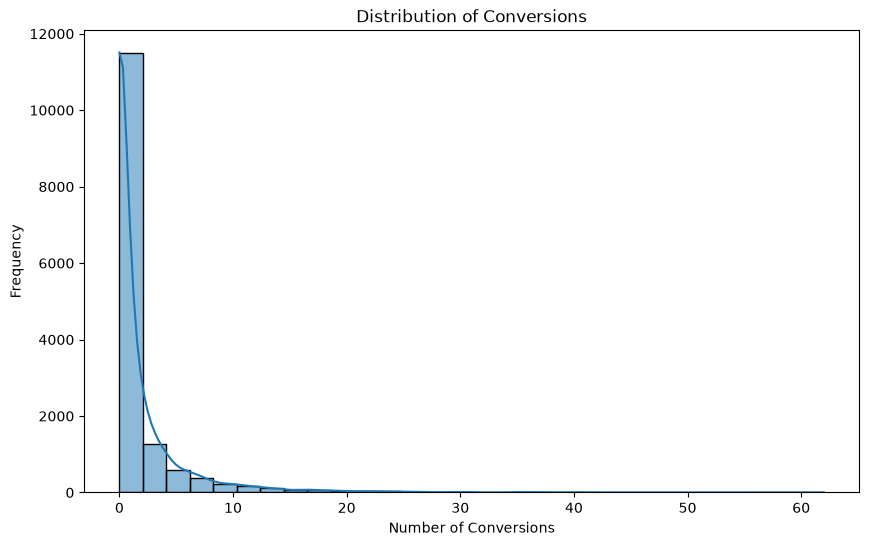

In [50]:
#Distribution of conversion
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='conversions',
    bins=30,
    kde=True,
    edgecolor='black'
)

plt.title('Distribution of Conversions')
plt.xlabel('Number of Conversions')
plt.ylabel('Frequency')
plt.show()

Insights:
Highly right-skewed distribution,which means a very few high values at the right side of the graph.The very tall bars near zero indicate that a large majority of records have low conversion counts

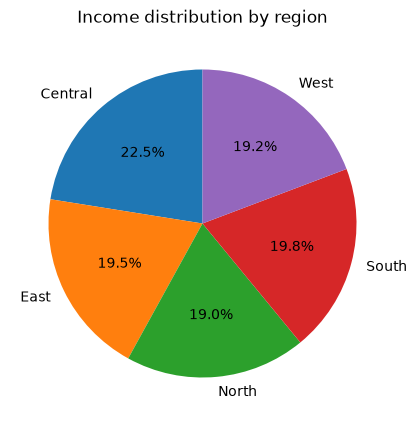

In [51]:
#Income distribution by region
region_counts = df.groupby("region")["income"].sum()
plt.figure(figsize=(8,5))
plt.pie(region_counts,labels=region_counts.index,autopct='%1.1f%%',startangle=90)
plt.title("Income distribution by region")
plt.show()

Insights:The Central region has the highest share of income at 22.5%, indicating the strongest contribution among all regions. In contrast, the North region has the lowest income share at 19.0%. However, the differences between regions are relatively small, suggesting that income distribution is fairly balanced across all regions.

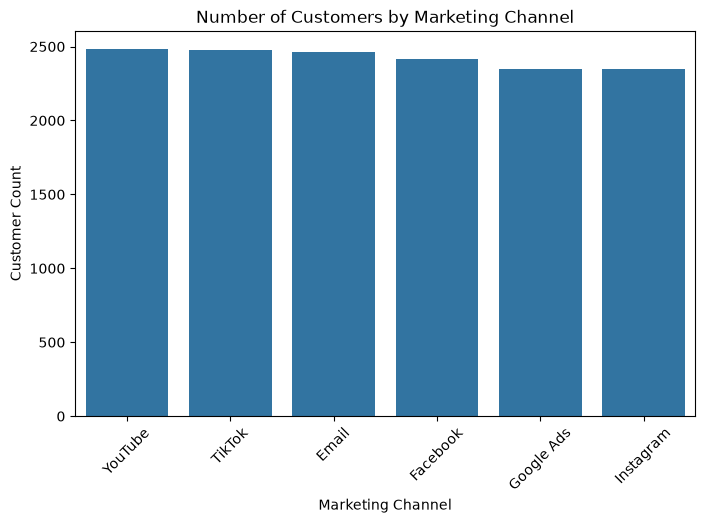

In [52]:
#No.of customers by marketing channel
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="channel",order=df['channel'].value_counts().index)
plt.title('Number of Customers by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Customer Count')
plt.xticks(rotation=45)
plt.show()
           

Insights:The number of customers is fairly evenly distributed across all marketing channels. YouTube has the highest customer count, closely followed by TikTok and Email, with only slight differences between them. Facebook has a moderately lower customer count, while Google Ads and Instagram have the lowest and nearly equal numbers of customers. Overall, the variation across channels is relatively small, indicating a balanced customer distribution among the marketing channels.

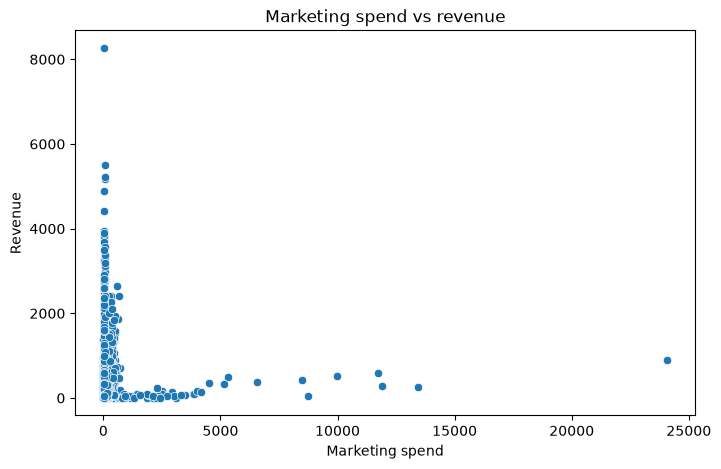

In [53]:
#Marketing spend vs revenue
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="spend",y="revenue")
plt.title("Marketing spend vs revenue")
plt.xlabel("Marketing spend")
plt.ylabel("Revenue")
plt.show()

Insights:The scatter plot suggests an inverse or negative relationship between marketing spend and revenue. Many observations with lower marketing spend show a wide range of revenue values, including some very high revenues.

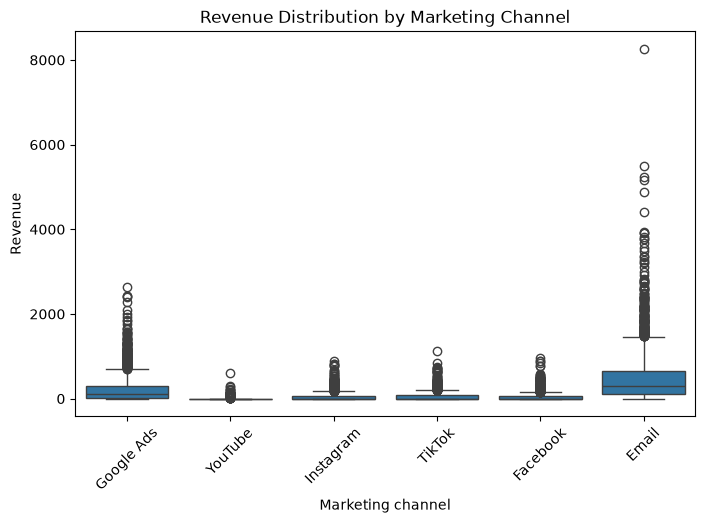

In [54]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="channel",y="revenue")
plt.title('Revenue Distribution by Marketing Channel')
plt.xlabel("Marketing channel")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

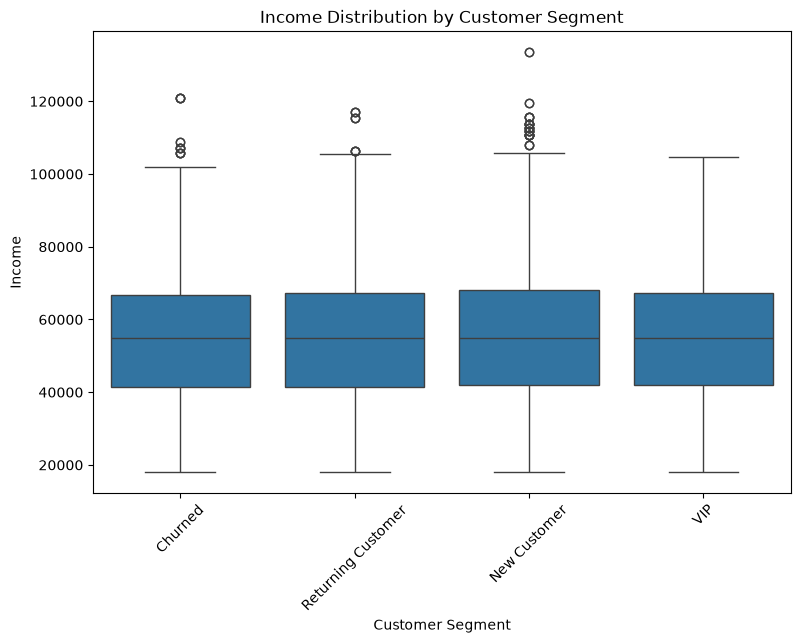

In [55]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='customer_segment',
    y='income'
)

plt.title('Income Distribution by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Income')

plt.xticks(rotation=45)
plt.show()

Insights:The income distribution is fairly similar across all customer segments.. The New Customer segment shows the highest number of upper-end outliers, indicating several customers with unusually high incomes. The Churned and Returning Customer segments also contain a few high-income outliers. In contrast, the VIP segment shows no visible outliers, suggesting a more consistent income distribution within that segment.

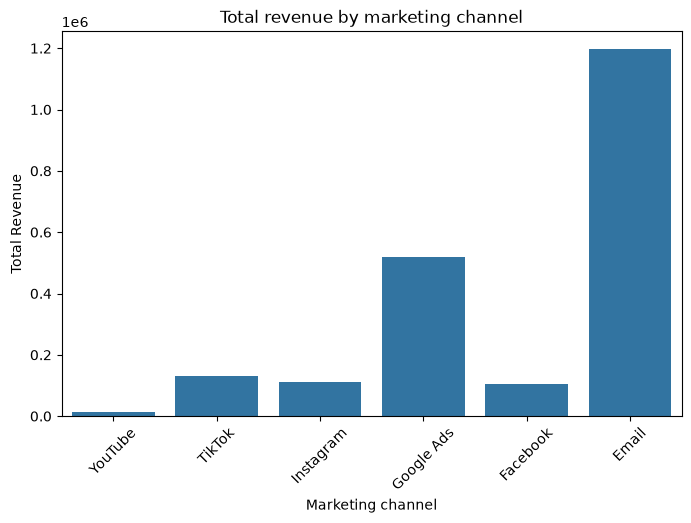

In [56]:
#Total revenue by marketing channel
channel_revenue = df.groupby("channel")["revenue"].sum().sort_index(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=channel_revenue.index,y=channel_revenue.values)
plt.title("Total revenue by marketing channel")
plt.xlabel("Marketing channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [57]:
import pandas as pd

df.to_csv("cleaned_data.csv", index=False)

Insights:Email is the highest-performing marketing channel in terms of total revenue, generating significantly more revenue than all other channels. Google Ads ranks second, while YouTube generates the lowest total revenue. TikTok, Instagram, and Facebook have relatively similar revenue levels, with only small differences between them. Overall, the results indicate that Email marketing is the dominant revenue-generating channel, followed by Google Ads.

## Final Conclusion

After performing data cleaning, statistical analysis, and extensive exploratory data analysis on the Marketing Campaign & Customer Behavior dataset, the following key conclusions were drawn:

## Customer Behavior

Customer behavior varies across different customer segments, regions, devices, and marketing channels.
Returning and VIP customers demonstrate stronger engagement and spending patterns compared to newer or churned customers, highlighting the importance of customer retention and loyalty.

## Marketing Campaign Performance

Different marketing campaigns show varying levels of revenue generation and customer engagement.
Some campaigns generate higher revenue and conversions, making them more effective for driving business results, while others show relatively lower performance and may require optimization.

## Channel Performance

Marketing performance differs across channels in terms of customer reach, clicks, conversions, spending, and revenue.
Standardizing the channel categories helped ensure that variations such as different spellings and naming conventions were treated as the same marketing channel, resulting in more reliable analysis.

## Customer Spending & Revenue

Customer income and spending patterns vary across different segments and regions.
Higher-value customers contribute significantly to overall revenue, making customer segmentation useful for identifying valuable customer groups and developing targeted marketing strategies.

## Campaign Engagement

Impressions, clicks, and conversions provide important insights into the effectiveness of marketing campaigns.
Higher impressions do not always result in higher conversions, indicating that campaign success depends not only on reach but also on the ability to engage customers and encourage them to take action.

## Customer Segmentation

The analysis shows meaningful differences between New, Returning, VIP, and Churned customers.
VIP and returning customers represent valuable segments that can be targeted through loyalty programs, personalized offers, and retention strategies, while churned customers may require targeted re-engagement campaigns.

## Data Quality & Reliability

After handling missing values, removing duplicate records, correcting data types, converting the mixed-format date column, and standardizing inconsistent categorical values such as marketing channels, the dataset became clean, consistent, reliable, and analysis-ready.


## FUTURE RECOMMENDATIONS

Based on the analysis of customer behavior, marketing campaigns, channels, and revenue patterns, the following data-driven business recommendations are suggested:

## Target High-Value Customers

Identify VIP and high-value customers and provide personalized offers, exclusive promotions, and loyalty rewards.
Focus on retention strategies to encourage repeat purchases and maximize customer lifetime value.

## Strengthen Customer Retention

Develop targeted campaigns for returning customers to maintain engagement and encourage repeat purchases.
Use personalized recommendations and loyalty benefits to build long-term customer relationships.

## Re-Engage Churned Customers

Launch targeted re-engagement campaigns for churned customers using limited-time offers, personalized discounts, and relevant promotions.
Analyze their previous behavior to identify suitable offers rather than using a one-size-fits-all approach.

## Optimize Marketing Channels

Allocate more marketing budget to channels that generate strong conversions and revenue.
Continuously compare channels based on impressions, clicks, conversions, spend, and revenue to identify the most effective channels.

## Improve Campaign Performance

Focus on campaigns that consistently generate higher engagement and revenue.
Review underperforming campaigns and optimize their targeting, offers, creative content, and promotional strategy.

## Improve Customer Engagement

Monitor the relationship between impressions, clicks, and conversions.
A campaign with high impressions but low clicks or conversions should be optimized to improve its messaging, creative design, and targeting.

## Personalized Marketing

Use customer characteristics such as age, income, region, device, and customer segment to create more targeted marketing campaigns.
Personalized offers can improve engagement and increase the likelihood of conversion.

## Optimize Marketing Spend

Monitor marketing spend against the revenue generated by each campaign and channel.
Prioritize campaigns that provide better returns and reconsider spending on campaigns that consistently generate low revenue relative to their cost.

## Regional & Device-Based Strategy

Analyze differences in customer behavior across regions and devices.
Use this information to create region-specific campaigns and optimize marketing content for the devices most frequently used by customers.

## Advanced Analytics (Next Step)

Apply predictive analytics to:

. Forecast campaign revenue

. Predict customer conversion

. Identify customers at risk of churn

. Estimate Customer Lifetime Value (CLV)

.  Recommend the most effective marketing channel for different customer segments

---------------------------------------------------------------------------------------------------------------------------
---------------------------------------------------------------------------------------------------------------------------